In [1]:
from pathlib import Path
import zipfile

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

URL = "https://ncses.nsf.gov/822/assets/0/files/college_grads_2023.zip"
DATA_DIR = Path("nscg_data")
ZIP_PATH = DATA_DIR / "college_grads_2023.zip"
CSV_NAME = "epcg23.csv"

In [2]:
# ---------------------------------------------------------------------------
# 1. Download (skipped if the zip is already there)
# ---------------------------------------------------------------------------
def download(url=URL, dest=ZIP_PATH):
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists():
        print(f"Already downloaded: {dest}")
        return dest
    print(f"Downloading {url} ...")
    headers = {"User-Agent": "Mozilla/5.0"}  # some government sites reject the default python UA
    with requests.get(url, headers=headers, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(dest, "wb") as f:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk)
    print(f"Saved {dest} ({dest.stat().st_size / 1e6:.1f} MB)")
    return dest


In [3]:
# ---------------------------------------------------------------------------
# 2. Extract + load into a DataFrame
# ---------------------------------------------------------------------------
def load(zip_path=ZIP_PATH):
    with zipfile.ZipFile(zip_path) as z:
        member = next(n for n in z.namelist() if n.lower().endswith(CSV_NAME))
        z.extract(member, DATA_DIR)          # also leaves the CSV on disk for reuse
        csv_path = DATA_DIR / member
    # read everything as text: many NSCG codes are strings with leading zeros ("01", "L" = logical skip)
    df = pd.read_csv(csv_path, dtype=str, low_memory=False)
    print(f"Loaded {csv_path}: {df.shape[0]:,} rows x {df.shape[1]} columns")
    return df

In [4]:
# ---------------------------------------------------------------------------
# 3. Sample + target  (reproduces 1,461 graduates / 1,240 positives / 221 negatives)
# ---------------------------------------------------------------------------
FIELDS = {  # N2DGRMED = detailed field of highest degree
    "116710": "CS", "116730": "CS", "116740": "CS", "116760": "CS", "116770": "CS",
    "128410": "Stats/OR/Applied math",   # applied mathematics
    "128430": "Stats/OR/Applied math",   # operations research
    "128440": "Stats/OR/Applied math",   # statistics
}

def build_sample(df):
    s = df[
        df.DGRDG.isin(["1", "2"])                       # highest degree: bachelor's or master's
        & df.N2DGRMED.isin(FIELDS)                      # data/AI-related field
        & df.DGRYR.astype(int).between(2018, 2022)      # graduated 2018-2022
        & df.LFSTAT.isin(["1", "2"])                    # in labor force (employed / unemployed)
    ].copy()

    s["w"] = s.WTSURVY.astype(float)                    # final survey weight
    hrs = pd.to_numeric(s.HRSWK)                        # 98 = logical skip (not working)
    employed = s.LFSTAT.eq("1")
    fulltime = employed & hrs.between(35, 97)
    related = s.OCEDRLP.isin(["1", "2"])                # closely / somewhat related to degree

    s["y"] = (fulltime & related).astype(int)
    s["outcome"] = np.select(
        [s.y.eq(1), ~employed, employed & ~fulltime],
        ["FT, degree-related", "Unemployed", "Part-time"],
        default="FT, not related",
    )

    # readable predictors
    s["degree"] = s.DGRDG.map({"1": "Bachelor's", "2": "Master's"})
    s["field"] = s.N2DGRMED.map(FIELDS)
    s["grad_yr"] = s.DGRYR
    s["sex"] = s.SEX_2023.map({"M": "Male", "F": "Female"})
    s["race"] = s.RACETHM.map({"1": "Asian", "3": "Black", "4": "Hispanic", "5": "White"}).fillna("Other/multiple")
    s["born_us"] = s.BTHUS.map({"Y": "US-born", "N": "Foreign-born"})
    s["school_loc"] = s.HDDGRUS.map({"Y": "US school", "N": "Non-US school"})
    print(f"\nSample: n = {len(s):,}  |  y=1: {s.y.sum():,}  |  y=0: {(s.y == 0).sum():,}")
    return s

In [5]:
# ---------------------------------------------------------------------------
# 4. Analysis helpers
# ---------------------------------------------------------------------------
def weighted_rate(y, w):
    """Weighted proportion with an approximate 95% CI (linearization, logit scale).
    The public file has no replicate weights / strata, so treat CIs as approximate."""
    y, w = np.asarray(y, float), np.asarray(w, float)
    n, p = len(y), np.sum(w * y) / np.sum(w)
    se = np.sqrt(n / (n - 1) * np.sum(w**2 * (y - p) ** 2)) / np.sum(w)
    if 0 < p < 1:
        logit, se_l = np.log(p / (1 - p)), se / (p * (1 - p))
        lo, hi = (1 / (1 + np.exp(-(logit + k * 1.96 * se_l))) for k in (-1, 1))
    else:
        lo = hi = np.nan
    return p, lo, hi


def subgroup_table(s, cols):
    rows = []
    for col in cols:
        for g, d in s.groupby(col):
            p, lo, hi = weighted_rate(d.y, d.w)
            n_eff = d.w.sum() ** 2 / (d.w**2).sum()          # Kish effective sample size
            n_neg = int((d.y == 0).sum())
            rows.append({
                "variable": col, "group": g, "n": len(d), "n_neg": n_neg, "n_eff": round(n_eff),
                "unweighted_%": round(d.y.mean() * 100, 1),
                "weighted_%": round(p * 100, 1),
                "ci_low": round(lo * 100, 1), "ci_high": round(hi * 100, 1),
                "caution": "small" if (n_neg < 10 or n_eff < 50) else "",
            })
    return pd.DataFrame(rows)


def plot_rates(tab, overall, path="subgroup_rates.png"):
    d = tab.iloc[::-1].reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(d) + 1.2))
    ax.axvline(overall, color="gray", ls="--", lw=1)
    for i, r in d.iterrows():
        ax.plot([r.ci_low, r.ci_high], [i, i], color="#2a78d6", lw=2)
        ax.plot(r["weighted_%"], i, "o", ms=8, mec="#2a78d6", mew=2,
                mfc="white" if r.caution else "#2a78d6")
    ax.set_yticks(range(len(d)))
    ax.set_yticklabels([f"{r.group} (n={r.n})" for _, r in d.iterrows()])
    ax.set_xlabel("% with full-time, degree-related job (weighted, 95% CI)")
    ax.set_title("Hollow dot = small cell; dashed line = overall", fontsize=9, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    print(f"Saved chart: {path}")

Saved nscg_data\college_grads_2023.zip (64.2 MB)
Loaded nscg_data\pcg23Public\epcg23.csv: 94,606 rows x 548 columns

Sample: n = 1,461  |  y=1: 1,240  |  y=0: 221

Population represented: 759,191 graduates
Kish effective n: 371 of 1461 (design effect ~ 3.9)

Full-time, degree-related job: unweighted 84.9% | weighted 78.4% (95% CI 73.2%-82.9%)

Outcome breakdown:
                        n  unweighted_%  weighted_%
outcome                                           
FT, degree-related  1240          84.9        78.4
FT, not related       67           4.6         6.2
Part-time             87           6.0         6.2
Unemployed            67           4.6         9.2

Subgroup rates:
   variable                 group    n  n_neg  n_eff  unweighted_%  weighted_%  ci_low  ci_high caution
    degree            Bachelor's  753    142    224          81.1        75.7    68.8     81.5        
    degree              Master's  708     79    159          88.8        84.2    76.0     89.9        
 

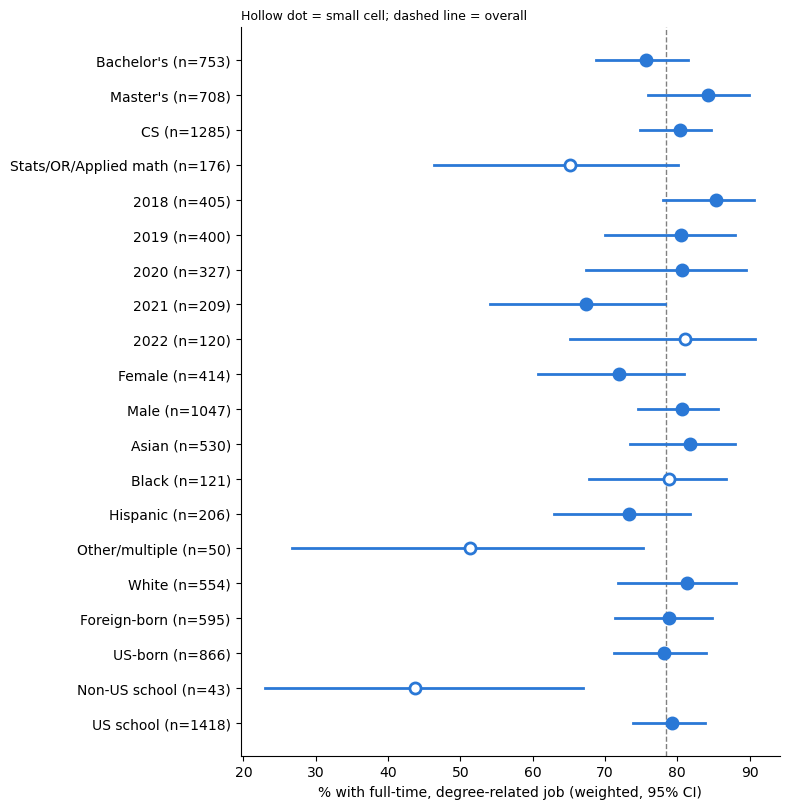

In [6]:
# ---------------------------------------------------------------------------
# Main
# ---------------------------------------------------------------------------
if __name__ == "__main__":
    df = load(download())
    s = build_sample(df)

    # -- How much do weights matter? -----------------------------------------
    n_eff = s.w.sum() ** 2 / (s.w**2).sum()
    print(f"\nPopulation represented: {s.w.sum():,.0f} graduates")
    print(f"Kish effective n: {n_eff:.0f} of {len(s)} (design effect ~ {len(s) / n_eff:.1f})")

    p, lo, hi = weighted_rate(s.y, s.w)
    print(f"\nFull-time, degree-related job: unweighted {s.y.mean():.1%} | "
          f"weighted {p:.1%} (95% CI {lo:.1%}-{hi:.1%})")

    # -- Outcome breakdown ---------------------------------------------------
    breakdown = pd.DataFrame({
        "n": s.outcome.value_counts(),
        "unweighted_%": (s.outcome.value_counts(normalize=True) * 100).round(1),
        "weighted_%": (s.groupby("outcome").w.sum() / s.w.sum() * 100).round(1),
    })
    print("\nOutcome breakdown:\n", breakdown)

    # -- Subgroup rates ------------------------------------------------------
    cols = ["degree", "field", "grad_yr", "sex", "race", "born_us", "school_loc"]
    tab = subgroup_table(s, cols)
    print("\nSubgroup rates:\n", tab.to_string(index=False))
    tab.to_csv("subgroup_rates.csv", index=False)
    plot_rates(tab, p * 100)

    # -- Weighted logistic regression (associations only) --------------------
    s["wn"] = s.w / s.w.mean()                     # normalize weights to mean 1
    formula = ("y ~ C(degree) + C(field, Treatment('CS')) + C(grad_yr, Treatment('2018'))"
               " + C(sex, Treatment('Male')) + C(race, Treatment('White'))"
               " + C(born_us, Treatment('US-born')) + C(school_loc, Treatment('US school'))")
    model = smf.glm(formula, data=s, family=sm.families.Binomial(),
                    var_weights=s.wn).fit(cov_type="HC1")   # robust SEs
    ci = np.exp(model.conf_int())
    odds = pd.DataFrame({"odds_ratio": np.exp(model.params), "ci_low": ci[0],
                         "ci_high": ci[1], "p_value": model.pvalues}).drop("Intercept").round(3)
    print("\nWeighted logistic regression (odds ratios):\n", odds.to_string())

    #  Salary & job satisfaction among those with the target job --
    pos = s[s.y == 1].copy()
    pos["salary"] = pd.to_numeric(pos.SALARY).where(lambda v: v < 9_999_998)  # 9999998 = skip
    pos["very_satisfied"] = pos.JOBSATIS.eq("1").astype(int)

    def wmedian(x, w):
        order = np.argsort(x.values)
        x, w = x.values[order], w.values[order]
        return x[np.searchsorted(np.cumsum(w), w.sum() / 2)]

    sec = pos.dropna(subset=["salary"]).groupby("degree").apply(
        lambda d: pd.Series({
            "n": len(d),
            "weighted_median_salary": wmedian(d.salary, d.w),
            "very_satisfied_%": round(weighted_rate(d.very_satisfied, d.w)[0] * 100, 1),
        }), include_groups=False)
    print("\nSalary & satisfaction (FT, degree-related only):\n", sec)